<a href="https://colab.research.google.com/github/anishsikdar1102-glitch/anish-sikdar-projects/blob/main/Exp_9_To_predict_whether_a_person_has_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# 1. Imports and Configurations
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier

DATA_FILE = "/content/dataset_diabetes_exp_9.csv"
TARGET_COLUMN = "Outcome"
OUTPUT_DIR = Path("exp9_results")
OUTPUT_DIR.mkdir(exist_ok=True)

In [6]:
# 2. Data Loading & Preprocessing
data_path = Path(DATA_FILE)
if not data_path.exists():
    raise FileNotFoundError(f"Could not find {DATA_FILE}.")

data = pd.read_csv(data_path)
print("Dataset shape:", data.shape)
print("Columns:", list(data.columns))

target_matches = [
    col for col in data.columns
    if str(col).strip().lower() == TARGET_COLUMN.lower()
]
if not target_matches:
    raise ValueError(f"Target column '{TARGET_COLUMN}' not found.")

target = target_matches[0]
data = data.dropna(subset=[target]).copy()

X = data.drop(columns=[target]).apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(data[target], errors="coerce").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Dataset shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [7]:
# 3. Model Definitions and Training
decision_tree = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42,
)

models = {
    "Decision Tree": make_pipeline(
        SimpleImputer(strategy="median"),
        decision_tree,
    ),
    "Bagging Classifier": make_pipeline(
        SimpleImputer(strategy="median"),
        BaggingClassifier(
            estimator=DecisionTreeClassifier(
                class_weight="balanced",
                random_state=42,
            ),
            n_estimators=100,
            max_samples=1.0,
            bootstrap=True,
            n_jobs=-1,
            random_state=42,
        ),
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        ),
    ),
}

# Train all models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Decision Tree trained successfully.
Bagging Classifier trained successfully.
Random Forest trained successfully.


In [8]:
# 4. Model Evaluation & Comparison
results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (diabetes)": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall (diabetes)": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 (diabetes)": f1_score(
            y_test, predictions, zero_division=0
        ),
    })

    print(f"\n{name} classification report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["No diabetes", "Diabetes"],
        zero_division=0,
    ))

    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(matrix, cmap="Blues")
    ax.set(
        title=f"Exp 9 — {name}",
        xlabel="Predicted",
        ylabel="Actual",
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["No diabetes", "Diabetes"],
        yticklabels=["No diabetes", "Diabetes"],
    )
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, str(value), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{name.lower().replace(' ', '_')}_confusion.png",
        dpi=150,
    )
    plt.close(fig)

results_df = pd.DataFrame(results).sort_values(
    "F1 (diabetes)", ascending=False
)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

print("\nModel Comparison Metrics:")
print(results_df.to_string(index=False))


Decision Tree classification report:
              precision    recall  f1-score   support

 No diabetes       0.75      0.83      0.79       100
    Diabetes       0.60      0.48      0.54        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.66       154
weighted avg       0.70      0.71      0.70       154


Bagging Classifier classification report:
              precision    recall  f1-score   support

 No diabetes       0.79      0.89      0.84       100
    Diabetes       0.74      0.57      0.65        54

    accuracy                           0.78       154
   macro avg       0.77      0.73      0.74       154
weighted avg       0.77      0.78      0.77       154


Random Forest classification report:
              precision    recall  f1-score   support

 No diabetes       0.81      0.87      0.84       100
    Diabetes       0.72      0.61      0.66        54

    accuracy                           0.78       154
   macro 

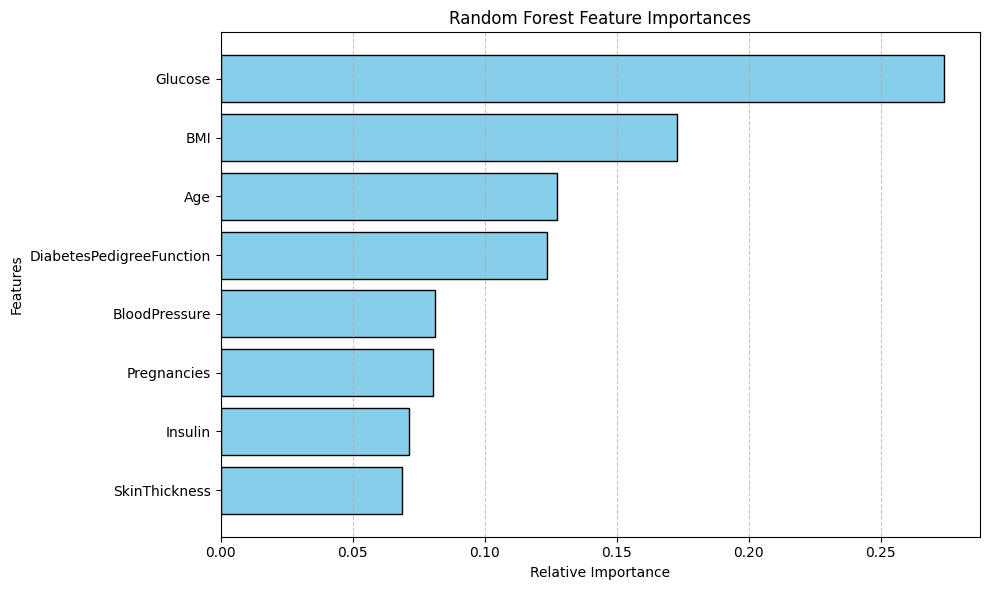

In [9]:
# 5. Visualize Feature Importance
importances = models["Random Forest"].named_steps["randomforestclassifier"].feature_importances_
feature_names = X.columns

feature_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df["Feature"], feature_imp_df["Importance"], color="skyblue", edgecolor="black")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importances")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### 📊 Comparative Analysis: Decision Tree vs. Bagging vs. Random Forest

Based on the evaluation metrics generated from the test set, here is a comparative breakdown of the three classifiers:

| Model | Accuracy | Precision (Diabetes) | Recall (Diabetes) | F1-Score (Diabetes) |
| :--- | :---: | :---: | :---: | :---: |
| **Random Forest** | **0.7792** | 0.7174 | **0.6111** | **0.6600** |
| **Bagging Classifier** | **0.7792** | **0.7381** | 0.5741 | 0.6458 |
| **Decision Tree** | 0.7078 | 0.6047 | 0.4815 | 0.5361 |

---

### 🔍 Key Insights & Trade-offs

#### 1. **The Power of Ensemble Learning (Bagging & Random Forest)**
* Both **Bagging** and **Random Forest** significantly outperform the standalone **Decision Tree** across all metrics (jumping from ~71% accuracy to nearly ~78%).
* Single decision trees are prone to **overfitting** and high variance. Bagging reduces this variance by averaging the predictions of 100 deep decision trees trained on bootstrap samples.

#### 2. **Bagging vs. Random Forest: The Feature Subspace Impact**
* While both models achieved the exact same overall accuracy (**77.92%**), their inner dynamics differ:
  * **Bagging Classifier** scored higher on **Precision (73.81%)** for the positive class (Diabetes). This means when it predicts diabetes, it is highly likely to be correct, leading to fewer false positives.
  * **Random Forest** scored higher on **Recall (61.11%)** and achieved the best overall **F1-score (0.66)**. In medical diagnostics, a higher recall is crucial because it means we miss fewer actual positive cases (fewer false negatives).
* **Why Random Forest won on Recall:** Unlike standard Bagging, Random Forest only considers a random subset of features at each split. This further decorrelates the individual trees, making the ensemble more robust and better at picking up subtle patterns across less dominant features (like BMI or Age) rather than just relying heavily on Glucose.